# Optical properties of multilayered marine particles

Companion of `sensitivity_marine_particles.ipynb` and `sensitivity_nonspherical_particles.ipynb`: impact of
an internal structure made of concentric layers of different refractive indices on the efficiency factors,
asymmetry parameter, backscattering ratio and scattering matrix, computed with exact multilayer Mie theory
([scattnlay](https://github.com/ovidiopr/scattnlay); Peña and Pal, 2009).

**Particle models** (refractive indices relative to seawater), inspired by the layered-sphere models of
phytoplankton (Kitchen and Zaneveld, 1992; Bernard et al., 2009):

* **two-layer**: a cytoplasm-like core ($m_{core}$ = 1.02) coated with a chloroplast-like shell of real index
  $m_{shell}$ = 1.06 to 1.20 occupying 10, 25 or 50 % of the particle volume,
* **three-layer**: core, chloroplast ($m_{shell}$ = 1.10, 25 % of the volume) and a thin outer wall (2 % of the
  radius) with a silica-like ($m_{wall}$ = 1.09, i.e. 1.46/1.34) or calcite-like ($m_{wall}$ = 1.19, 1.6/1.34)
  index,
* each layered particle is compared with the **homogeneous sphere of volume-averaged refractive index**
  $\bar{m} = \sum_k v_k m_k$, the usual equivalent of a structured particle.

**Absorption**: non-absorbing particles, or pigments confined to the chloroplast layer. The volume-averaged
imaginary part is the `pigment` spectrum of the companion notebook, so the layered particle and its
homogeneous equivalent contain the same amount of absorbing material, only distributed differently.

**Assumptions**: same size distributions of the outer radius ($r \le$ 40 µm), the same relative layer radii for
all sizes, wavelengths in water ($n_w$ = 1.34) at the OLCI bands.

**Requirements**: `pip install scattnlay` (GPL-3.0). If its import fails with
`GLIBCXX_3.4.32 not found` in an Anaconda environment, update the C++ runtime of the environment
(`conda install -c conda-forge "libstdcxx-ng>=13"`) or start Jupyter with
`LD_PRELOAD=/usr/lib/x86_64-linux-gnu/libstdc++.so.6`. The computations take about 2 minutes on 40 CPUs.

## 1. Setup

In [1]:
import os

# one BLAS thread per process: the scattering computations run in one process per CPU,
# and multithreaded BLAS in each of them oversubscribes the CPUs (and can stall the workers)
for var in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ[var] = '1'

import time

import dask
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.patches import Circle
from scattnlay import scattcoeffs, scattnlay

from mopsmap_tbx.opac_mopsmap import ROOT

odir = ROOT / 'scatmat' / 'sensitivity'
odir.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'font.size': 11, 'axes.titlesize': 11, 'axes.labelsize': 11, 'legend.fontsize': 9,
    'axes.edgecolor': '#c3c2b7', 'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6,
    'lines.linewidth': 1.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'figure.dpi': 100, 'savefig.dpi': 200,
})
FV_COLORS = ['#86b6ef', '#2a78d6', '#104281']           # shell volume fraction (ordinal)
CAT = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']      # categorical
HOMOG = '#5f5e5a'                                       # homogeneous equivalent spheres
print('dask', dask.__version__)

dask 2024.8.0


In [2]:
n_w = 1.34
wl = np.array([400, 412.5, 442.5, 490, 510, 560, 620, 665, 673.75, 681.25,
               708.75, 753.75, 778.75, 865, 885, 900])  # OLCI bands (nm, vacuum)
wl_w = wl * 1e-3 / n_w                                  # wavelength in water (µm)

r_min, r_max = 0.05, 40.                                # outer radius (µm)
r = np.logspace(np.log10(r_min), np.log10(r_max), 1200)
theta = np.concatenate([[0, 0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.3, 0.4], np.arange(0.5, 180.1, 0.5)])
mu = np.cos(np.radians(theta))


def junge(r, xi):
    return r ** -xi


def lognormal(r, r_mod, sigma):
    return np.exp(-0.5 * (np.log(r / r_mod) / np.log(sigma)) ** 2) / r


def gauss(lam, lam0, s):
    return np.exp(-0.5 * ((lam - lam0) / s) ** 2)


psd_def = {
    'J3.0': ('Junge', 'ξ = 3.0', junge(r, 3.0)),
    'J3.5': ('Junge', 'ξ = 3.5', junge(r, 3.5)),
    'J4.0': ('Junge', 'ξ = 4.0', junge(r, 4.0)),
    'J4.5': ('Junge', 'ξ = 4.5', junge(r, 4.5)),
    'LN0.5': ('log-normal', 'r_mod = 0.5 µm', lognormal(r, 0.5, 1.8)),
    'LN1': ('log-normal', 'r_mod = 1 µm', lognormal(r, 1., 1.8)),
    'LN2': ('log-normal', 'r_mod = 2 µm', lognormal(r, 2., 1.8)),
    'LN5': ('log-normal', 'r_mod = 5 µm', lognormal(r, 5., 1.8)),
}
psd_ids = list(psd_def)
dr = np.gradient(r)
n_r = np.array([v[2] / np.sum(v[2] * dr) for v in psd_def.values()])
weights = n_r * dr                                       # (psd, r) quadrature weights

# volume-averaged imaginary part (pigment spectrum of the companion notebook)
mi_pigment = 2e-4 + 3e-3 * gauss(wl, 442.5, 35) + 1.5e-3 * gauss(wl, 675, 15)

## 2. Particle models

Layers are described by their outer radius relative to the particle radius, from the core to the outer layer.
The pigments of the `pigment` case are confined to the chloroplast layer, with
$m_{i,shell} = \bar{m}_i / v_{shell}$ so that the volume-averaged imaginary part is the same for all models.

In [3]:
m_core = 1.02
m_shells = [1.06, 1.10, 1.15, 1.20]
f_vs = [0.10, 0.25, 0.50]                 # shell volume fraction (two-layer)
walls = {'silica': 1.09, 'calcite': 1.19}
m_chl, f_chl, wall_thickness = 1.10, 0.25, 0.02
absorptions = ['none', 'pigment']


def two_layer(m_shell, f_v, absorption, structure):
    # relative layer radii and refractive indices (wl, layer) of the two-layer model
    mi = mi_pigment if absorption == 'pigment' else np.zeros_like(wl)
    if structure == 'homogeneous':
        m_eq = (1 - f_v) * m_core + f_v * m_shell
        return np.array([1.]), (m_eq + 1j * mi)[:, None]
    frac = np.array([(1 - f_v) ** (1 / 3), 1.])
    m = np.stack([np.full(len(wl), m_core + 0j), m_shell + 1j * mi / f_v], axis=1)
    return frac, m


def three_layer(wall, absorption, structure):
    # core / chloroplast / wall
    mi = mi_pigment if absorption == 'pigment' else np.zeros_like(wl)
    v_wall = 1 - (1 - wall_thickness) ** 3
    v_core = 1 - f_chl - v_wall
    if structure == 'homogeneous':
        m_eq = v_core * m_core + f_chl * m_chl + v_wall * walls[wall]
        return np.array([1.]), (m_eq + 1j * mi)[:, None]
    frac = np.array([v_core ** (1 / 3), (1 - v_wall) ** (1 / 3), 1.])
    m = np.stack([np.full(len(wl), m_core + 0j), m_chl + 1j * mi / f_chl,
                  np.full(len(wl), walls[wall] + 0j)], axis=1)
    return frac, m


rows = []
for m_shell in m_shells:
    for f_v in f_vs:
        frac, m = two_layer(m_shell, f_v, 'pigment', 'layered')
        rows.append(('two-layer', f'm_shell = {m_shell:.2f}, f_v = {f_v:.2f}', np.round(frac, 3),
                     (1 - f_v) * m_core + f_v * m_shell, m[5, -1].imag))
for wall, mw in walls.items():
    frac, m = three_layer(wall, 'pigment', 'layered')
    m_eq = three_layer(wall, 'none', 'homogeneous')[1][0, 0].real
    rows.append(('three-layer', f'{wall} wall (m = {mw})', np.round(frac, 3), m_eq, m[5, 1].imag))
pd.DataFrame(rows, columns=['model', 'case', 'relative radii', 'volume-averaged m_r', 'm_i chloroplast (560 nm)'])

,model,case,relative radii,volume-averaged m_r,m_i chloroplast (560 nm)
0,two-layer,"m_shell = 1.06, f_v = 0.10","[0.965, 1.0]",1.024000,0.002107
1,two-layer,"m_shell = 1.06, f_v = 0.25","[0.909, 1.0]",1.030000,0.000843
2,two-layer,"m_shell = 1.06, f_v = 0.50","[0.794, 1.0]",1.040000,0.000421
3,two-layer,"m_shell = 1.10, f_v = 0.10","[0.965, 1.0]",1.028000,0.002107
4,two-layer,"m_shell = 1.10, f_v = 0.25","[0.909, 1.0]",1.040000,0.000843
5,two-layer,"m_shell = 1.10, f_v = 0.50","[0.794, 1.0]",1.060000,0.000421
6,two-layer,"m_shell = 1.15, f_v = 0.10","[0.965, 1.0]",1.033000,0.002107
7,two-layer,"m_shell = 1.15, f_v = 0.25","[0.909, 1.0]",1.052500,0.000843
8,two-layer,"m_shell = 1.15, f_v = 0.50","[0.794, 1.0]",1.085000,0.000421
9,two-layer,"m_shell = 1.20, f_v = 0.10","[0.965, 1.0]",1.038000,0.002107


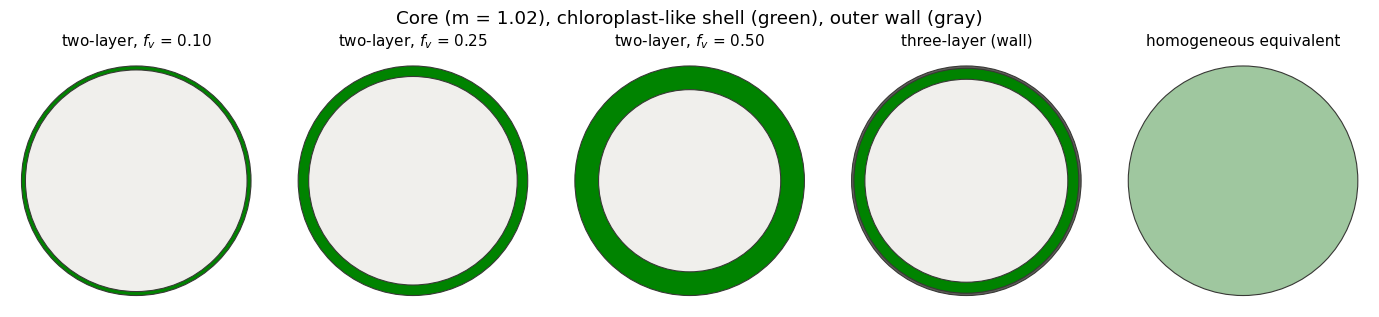

In [4]:
fig, axs = plt.subplots(1, 5, figsize=(14, 3.2))
models = [('two-layer, $f_v$ = 0.10', two_layer(1.10, 0.10, 'none', 'layered')[0], ['#f0efec', '#008300']),
          ('two-layer, $f_v$ = 0.25', two_layer(1.10, 0.25, 'none', 'layered')[0], ['#f0efec', '#008300']),
          ('two-layer, $f_v$ = 0.50', two_layer(1.10, 0.50, 'none', 'layered')[0], ['#f0efec', '#008300']),
          ('three-layer (wall)', three_layer('silica', 'none', 'layered')[0], ['#f0efec', '#008300', '#5f5e5a']),
          ('homogeneous equivalent', np.array([1.]), ['#9fc79f'])]
for ax, (title, frac, colors) in zip(axs, models):
    for f, c in zip(frac[::-1], colors[::-1]):
        ax.add_patch(Circle((0, 0), f, facecolor=c, edgecolor='#383835', lw=0.8))
    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(title)
fig.suptitle('Core (m = 1.02), chloroplast-like shell (green), outer wall (gray)')
plt.tight_layout()

## 3. Multilayer Mie computations

For each particle, `scattcoeffs` gives the multipole coefficients $a_n, b_n$ of the layered sphere and `scattnlay`
the efficiency factors and asymmetry parameter. The amplitude functions are summed as
$S_1 = \sum_n \frac{2n+1}{n(n+1)} (a_n \pi_n + b_n \tau_n)$ and $S_2 = \sum_n \frac{2n+1}{n(n+1)} (a_n \tau_n + b_n \pi_n)$,
with the angular functions $\pi_n(\cos\theta)$, $\tau_n(\cos\theta)$ tabulated once for all scattering angles,
which is about 1000 times faster than computing them for each particle. The scattering matrix elements are
normalized as in MOPSMAP: $a_1 = a_2 = 4\langle S_{11}\rangle / \langle x^2 Q_{sca}\rangle$,
$a_3 = a_4 \propto \langle S_{33}\rangle$, $b_1 \propto \langle S_{12}\rangle$, $b_2 \propto -\langle S_{34}\rangle$
(Bohren and Huffman, 1983, with $\int S_{11} d\Omega = \pi x^2 Q_{sca}$).

In [5]:
NMAX = 1200   # larger than the number of terms needed for x = 842 (1025)


def angular_functions(mu, nmax=NMAX):
    # pi_n and tau_n (n = 0..nmax) at the cosines mu
    pi = np.zeros((nmax + 1, len(mu)))
    tau = np.zeros_like(pi)
    pi[1] = 1.
    for n in range(2, nmax + 1):
        pi[n] = ((2 * n - 1) * mu * pi[n - 1] - n * pi[n - 2]) / (n - 1)
    n = np.arange(1, nmax + 1)[:, None]
    tau[1:] = n * mu * pi[1:] - (n + 1) * pi[:-1]
    return pi, tau


def amplitudes(x_layers, m_layers, pi, tau):
    # S1, S2 of a layered sphere from its multipole coefficients
    terms, an, bn = scattcoeffs(x_layers, m_layers)
    n = np.arange(1, len(an) + 1)
    f = (2 * n + 1) / (n * (n + 1))
    A, B = f * an, f * bn
    P, T = pi[1:len(an) + 1], tau[1:len(an) + 1]
    return A @ P + B @ T, A @ T + B @ P


# check against scattnlay's own amplitude functions, and identical layers against a homogeneous sphere
pi, tau = angular_functions(mu)
for x, frac, m in [(100., [1.], [1.05 + 0.002j]), (300., [0.8, 1.], [1.02, 1.10 + 0.003j]),
                   (842., [0.6, 0.98, 1.], [1.02, 1.10 + 0.003j, 1.20])]:
    X, M = x * np.array(frac), np.array(m, complex)
    S1, S2 = amplitudes(X, M, pi, tau)
    ref = scattnlay(X, M, np.radians(theta))
    err = np.max(np.abs((np.abs(S1) ** 2 + np.abs(S2) ** 2) / (np.abs(ref[8]) ** 2 + np.abs(ref[9]) ** 2) - 1))
    print(f'x = {x:5.0f}, {len(m)} layer(s): max relative difference of S11 = {err:.1e}')
X = 300. * np.array([0.7, 1.])
q2 = scattnlay(X, np.array([1.1 + 0.003j] * 2))
q1 = scattnlay(X[-1:], np.array([1.1 + 0.003j]))
print(f'identical layers vs homogeneous: Qext {q2[1]:.10f} / {q1[1]:.10f}, g {q2[6]:.10f} / {q1[6]:.10f}')

x =   100, 1 layer(s): max relative difference of S11 = 2.7e-14


x =   300, 2 layer(s): max relative difference of S11 = 1.5e-14


x =   842, 3 layer(s): max relative difference of S11 = 8.2e-15
identical layers vs homogeneous: Qext 2.0485515867 / 2.0485515867, g 0.9901094611 / 0.9901094611


In [6]:
@dask.delayed
def multilayer_case(frac, m_layers, wl_w, r, mu, weights):
    # size-averaged Qext, ssa, g (psd,) and scattering matrix (psd, theta, element) at one wavelength
    import numpy as np
    from scattnlay import scattnlay

    pi, tau = angular_functions(mu)
    k = 2 * np.pi / wl_w
    qext, qsca, g = (np.empty(len(r)) for _ in range(3))
    S11, S12, S33, S34 = (np.empty((len(r), len(mu))) for _ in range(4))
    for i, ri in enumerate(r):
        X = np.asarray(frac) * k * ri
        out = scattnlay(X, m_layers)
        qext[i], qsca[i], g[i] = out[1], out[2], out[6]
        S1, S2 = amplitudes(X, m_layers, pi, tau)
        S11[i] = (np.abs(S2) ** 2 + np.abs(S1) ** 2) / 2
        S12[i] = (np.abs(S2) ** 2 - np.abs(S1) ** 2) / 2
        S33[i] = np.real(S2 * np.conj(S1))
        S34[i] = np.imag(S2 * np.conj(S1))
    x = k * r
    G = np.pi * r ** 2
    Qext = weights @ (G * qext) / (weights @ G)
    Qsca = weights @ (G * qsca) / (weights @ G)
    gg = weights @ (G * qsca * g) / (weights @ (G * qsca))
    den = (weights @ (x ** 2 * qsca))[:, None] / 4
    a1, a3 = weights @ S11 / den, weights @ S33 / den
    b1, b2 = weights @ S12 / den, -(weights @ S34) / den
    return Qext, Qsca / Qext, gg, np.stack([a1, a1, a3, a3, b1, b2], axis=-1).astype('float32')


structures = ['layered', 'homogeneous']
keys2 = [(s, a, ms, fv) for s in structures for a in absorptions for ms in m_shells for fv in f_vs]
keys3 = [(s, a, w) for s in structures for a in absorptions for w in walls]
tasks = []
for key in keys2:
    frac, m = two_layer(key[2], key[3], key[1], key[0])
    tasks += [multilayer_case(frac, m[iw], wl_w[iw], r, mu, weights) for iw in range(len(wl))]
for key in keys3:
    frac, m = three_layer(key[2], key[1], key[0])
    tasks += [multilayer_case(frac, m[iw], wl_w[iw], r, mu, weights) for iw in range(len(wl))]
print(len(keys2) + len(keys3), 'particle models,', len(tasks), 'tasks')
t0 = time.perf_counter()
res = dask.compute(*tasks, scheduler='processes', num_workers=os.cpu_count())
print(f'done in {time.perf_counter() - t0:.0f} s')

56 particle models, 896 tasks


done in 129 s


### Gathering the results

In [7]:
elements = ['a1', 'a2', 'a3', 'a4', 'b1', 'b2']


def gather(res, shape, dims, coords):
    # results ordered as (cases..., wl) with arrays over psd -> Dataset (cases..., wl, psd)
    out = [np.array([x[i] for x in res]) for i in range(4)]
    out = [o.reshape(shape + (len(wl),) + o.shape[1:]) for o in out]
    d = dims + ('wl', 'psd')
    ds = xr.Dataset({'Qext': (d, out[0]), 'ssa': (d, out[1]), 'g': (d, out[2]),
                     'F': (d + ('theta', 'element'), out[3])},
                    coords=dict(coords, wl=wl, psd=psd_ids, theta=theta, element=elements))
    ds = ds.assign_coords(theta_rad=('theta', np.radians(theta)))
    a1 = ds.F.sel(element='a1')
    a1s = a1 * np.sin(ds.theta_rad)
    ds['bb_ratio'] = a1s.where(ds.theta >= 90, drop=True).integrate('theta_rad') / a1s.integrate('theta_rad')
    ds['Qsca'] = ds.Qext * ds.ssa
    ds['Qabs'] = ds.Qext - ds.Qsca
    ds['Qbb'] = ds.Qsca * ds.bb_ratio
    ds['dolp'] = -ds.F.sel(element='b1') / a1
    return ds


n2 = len(keys2) * len(wl)
ds2 = gather(res[:n2], (len(structures), len(absorptions), len(m_shells), len(f_vs)),
             ('structure', 'absorption', 'm_shell', 'f_v'),
             dict(structure=structures, absorption=absorptions, m_shell=m_shells, f_v=f_vs))
ds2 = ds2.assign_coords(m_eq=(('m_shell', 'f_v'), (1 - np.array(f_vs)) * m_core + np.outer(m_shells, f_vs)))
ds3 = gather(res[n2:], (len(structures), len(absorptions), len(walls)), ('structure', 'absorption', 'wall'),
             dict(structure=structures, absorption=absorptions, wall=list(walls)))
ds2

<xarray.Dataset> Size: 64MB
Dimensions:     (structure: 2, absorption: 2, m_shell: 4, f_v: 3, wl: 16,
                 psd: 8, theta: 369, element: 6)
Coordinates:
  * structure   (structure) <U11 88B 'layered' 'homogeneous'
  * absorption  (absorption) <U7 56B 'none' 'pigment'
  * m_shell     (m_shell) float64 32B 1.06 1.1 1.15 1.2
  * f_v         (f_v) float64 24B 0.1 0.25 0.5
  * wl          (wl) float64 128B 400.0 412.5 442.5 490.0 ... 865.0 885.0 900.0
  * psd         (psd) <U5 160B 'J3.0' 'J3.5' 'J4.0' 'J4.5' ... 'LN1' 'LN2' 'LN5'
  * theta       (theta) float64 3kB 0.0 0.001 0.005 0.01 ... 179.0 179.5 180.0
  * element     (element) <U2 48B 'a1' 'a2' 'a3' 'a4' 'b1' 'b2'
    theta_rad   (theta) float64 3kB 0.0 1.745e-05 8.727e-05 ... 3.133 3.142
    m_eq        (m_shell, f_v) float64 96B 1.024 1.03 1.04 ... 1.038 1.065 1.11
Data variables:
    Qext        (structure, absorption, m_shell, f_v, wl, psd) float64 49kB 1...
    ssa         (structure, absorption, m_shell, f_v, wl, psd) float64 49kB 1...
    g           (structure, absorption, m_shell, f_v, wl, psd) float64 49kB 0...
    F           (structure, absorption, m_shell, f_v, wl, psd, theta, element) float32 54MB ...
    bb_ratio    (structure, absorption, m_shell, f_v, wl, psd) float64 49kB 0...
    Qsca        (structure, absorption, m_shell, f_v, wl, psd) float64 49kB 1...
    Qabs        (structure, absorption, m_shell, f_v, wl, psd) float64 49kB -...
    Qbb         (structure, absorption, m_shell, f_v, wl, psd) float64 49kB 0...
    dolp        (structure, absorption, m_shell, f_v, wl, psd, theta) float32 9MB ...

## 4. Layered vs homogeneous particles

### Two-layer particles as a function of the volume-averaged refractive index

Non-absorbing particles at 560 nm. Homogeneous spheres (gray) and two-layer particles (colored by shell volume
fraction, one point per $m_{shell}$ = 1.06, 1.10, 1.15, 1.20) are plotted against the same volume-averaged
refractive index $\bar{m}_r$.

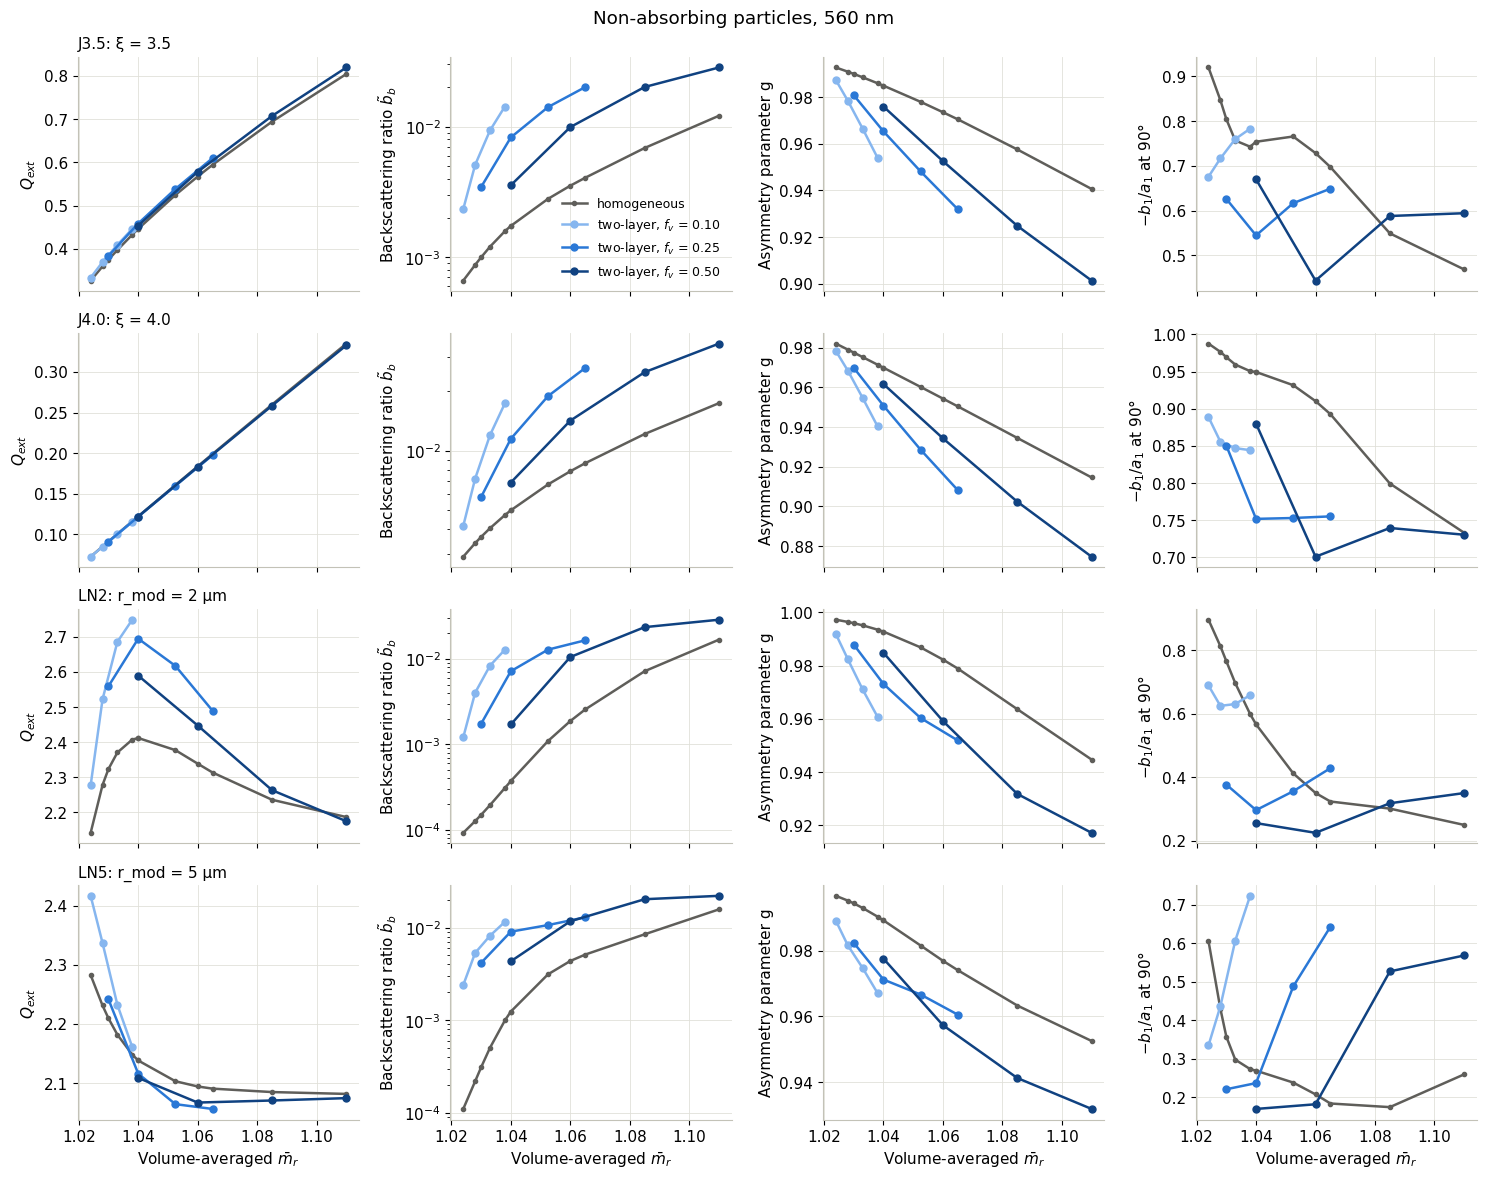

In [8]:
panels = [('Qext', '$Q_{ext}$'), ('bb_ratio', 'Backscattering ratio $\\tilde{b}_b$'), ('g', 'Asymmetry parameter g'),
          ('dolp90', '$-b_1/a_1$ at 90°')]
sub = ds2.sel(absorption='none', wl=560)
sub['dolp90'] = sub.dolp.sel(theta=90)
psds = ['J3.5', 'J4.0', 'LN2', 'LN5']
fig, axs = plt.subplots(len(psds), 4, figsize=(15, 3 * len(psds)), sharex=True)
for i, p in enumerate(psds):
    for j, (v, label) in enumerate(panels):
        ax = axs[i, j]
        h = sub[v].sel(structure='homogeneous', psd=p)
        order = np.argsort(sub.m_eq.values.ravel())
        ax.plot(sub.m_eq.values.ravel()[order], h.values.ravel()[order], 'o-', ms=3, color=HOMOG, label='homogeneous')
        for fv, c in zip(f_vs, FV_COLORS):
            lay = sub[v].sel(structure='layered', psd=p, f_v=fv)
            ax.plot(sub.m_eq.sel(f_v=fv), lay, 'o-', ms=5, color=c, label=f'two-layer, $f_v$ = {fv:.2f}')
        if v == 'bb_ratio':
            ax.set_yscale('log')
        ax.set_ylabel(label)
    axs[i, 0].set_title(f'{p}: {psd_def[p][1]}', loc='left')
for ax in axs[-1]:
    ax.set_xlabel('Volume-averaged $\\bar{m}_r$')
axs[0, 1].legend(frameon=False)
fig.suptitle('Non-absorbing particles, 560 nm')
plt.tight_layout()

### Ratio of layered to homogeneous particles

Range over the eight size distributions at 560 nm (non-absorbing).

In [9]:
sub = ds2.sel(absorption='none', wl=560)
rows = {}
for v in ['Qext', 'bb_ratio', 'g']:
    ratio = sub[v].sel(structure='layered') / sub[v].sel(structure='homogeneous')
    for fv in f_vs:
        rows[(v, f'f_v = {fv:.2f}')] = [f'{float(ratio.sel(m_shell=ms, f_v=fv).min()):.2f}–'
                                        f'{float(ratio.sel(m_shell=ms, f_v=fv).max()):.2f}' for ms in m_shells]
table = pd.DataFrame(rows, index=[f'm_shell = {ms:.2f}' for ms in m_shells]).T
table

m_shell = 1.06 m_shell = 1.10 m_shell = 1.15  \
Qext     f_v = 0.10      0.95–1.06      0.94–1.11      0.94–1.13   
         f_v = 0.25      0.96–1.10      0.95–1.12      0.94–1.11   
         f_v = 0.50      0.96–1.07      0.96–1.09      0.95–1.09   
bb_ratio f_v = 0.10     1.02–21.71     1.16–32.03     1.38–43.25   
         f_v = 0.25     1.08–13.40     1.30–19.43     1.53–18.71   
         f_v = 0.50      1.09–4.61      1.25–6.31      1.40–5.03   
g        f_v = 0.10      0.99–1.00      0.98–0.99      0.97–0.99   
         f_v = 0.25      0.99–1.00      0.97–0.99      0.96–0.98   
         f_v = 0.50      0.99–0.99      0.98–0.98      0.96–0.98   

                    m_shell = 1.20  
Qext     f_v = 0.10      0.94–1.14  
         f_v = 0.25      0.94–1.12  
         f_v = 0.50      0.95–1.08  
bb_ratio f_v = 0.10     1.61–49.33  
         f_v = 0.25     1.70–15.19  
         f_v = 0.50      1.40–3.95  
g        f_v = 0.10      0.96–0.98  
         f_v = 0.25      0.94–0.99  
         f_v = 0.50      0.95–0.98

### Scattering matrix

Two-layer particles with $f_v$ = 0.25 (solid) and their homogeneous equivalents (dashed), non-absorbing, 560 nm.

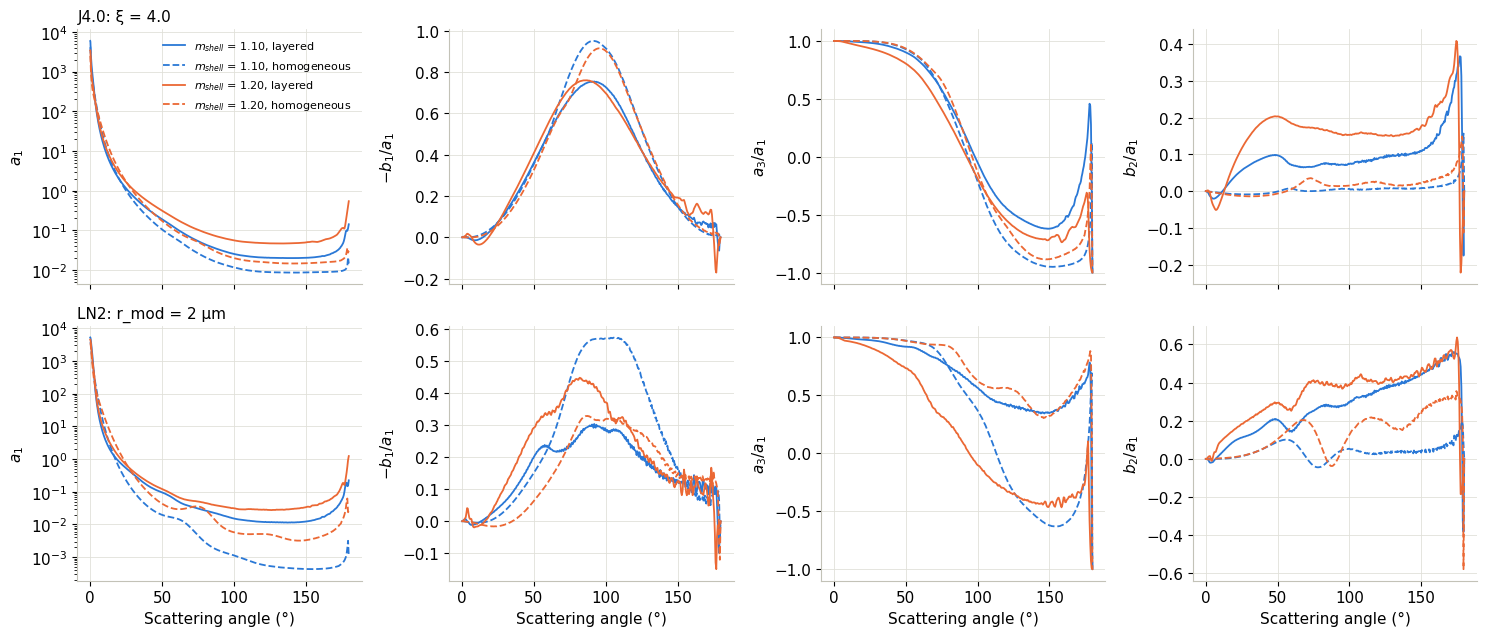

In [10]:
panels = [('a1', '$a_1$'), ('dolp', '$-b_1/a_1$'), ('a3', '$a_3/a_1$'), ('b2', '$b_2/a_1$')]
fig, axs = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True)
for i, p in enumerate(['J4.0', 'LN2']):
    s = ds2.sel(absorption='none', wl=560, psd=p, f_v=0.25)
    for ms, c in zip([1.10, 1.20], CAT):
        for st, ls in [('layered', '-'), ('homogeneous', '--')]:
            d = s.sel(m_shell=ms, structure=st)
            a1 = d.F.sel(element='a1')
            lab = f'$m_{{shell}}$ = {ms:.2f}, {st}'
            for j, (v, label) in enumerate(panels):
                y = a1 if v == 'a1' else d.dolp if v == 'dolp' else d.F.sel(element=v) / a1
                axs[i, j].plot(d.theta, y, ls=ls, color=c, lw=1.3, label=lab)
                axs[i, j].set_ylabel(label)
    axs[i, 0].set_yscale('log')
    axs[i, 0].set_title(f'{p}: {psd_def[p][1]}', loc='left')
for ax in axs[1]:
    ax.set_xlabel('Scattering angle (°)')
axs[0, 0].legend(frameon=False, fontsize=8)
plt.tight_layout()

### Absorption: pigments confined to the chloroplast layer

$Q_{abs}$ of two-layer particles relative to their homogeneous equivalents (same amount of pigment), and single
scattering albedo, for $m_{shell}$ = 1.10.

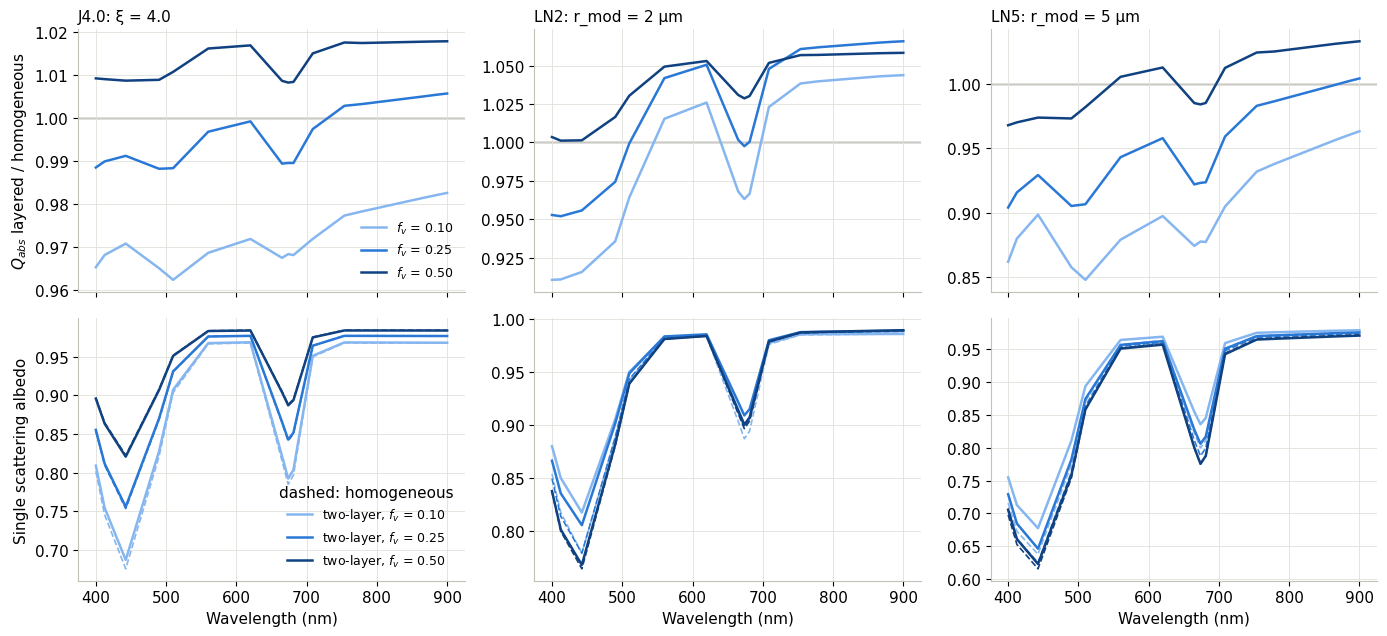

In [11]:
psds = ['J4.0', 'LN2', 'LN5']
fig, axs = plt.subplots(2, len(psds), figsize=(14, 6.5), sharex=True)
for j, p in enumerate(psds):
    s = ds2.sel(absorption='pigment', psd=p, m_shell=1.10)
    for fv, c in zip(f_vs, FV_COLORS):
        d = s.sel(f_v=fv)
        axs[0, j].plot(wl, d.Qabs.sel(structure='layered') / d.Qabs.sel(structure='homogeneous'), color=c,
                       label=f'$f_v$ = {fv:.2f}')
        axs[1, j].plot(wl, d.ssa.sel(structure='layered'), color=c, label=f'two-layer, $f_v$ = {fv:.2f}')
        axs[1, j].plot(wl, d.ssa.sel(structure='homogeneous'), '--', color=c, lw=1.2)
    axs[0, j].axhline(1, color=HOMOG, lw=1, zorder=-1)
    axs[0, j].set_title(f'{p}: {psd_def[p][1]}', loc='left')
    axs[1, j].set_xlabel('Wavelength (nm)')
axs[0, 0].set_ylabel('$Q_{abs}$ layered / homogeneous')
axs[1, 0].set_ylabel('Single scattering albedo')
axs[0, 0].legend(frameon=False)
axs[1, 0].legend(frameon=False, title='dashed: homogeneous')
plt.tight_layout()

### Three-layer particles: effect of an outer wall

Core, chloroplast ($m_{shell}$ = 1.10, $f_v$ = 0.25, with pigments) and a wall of 2 % of the radius, compared with the
two-layer particle without wall (solid: layered, dashed: homogeneous equivalent).

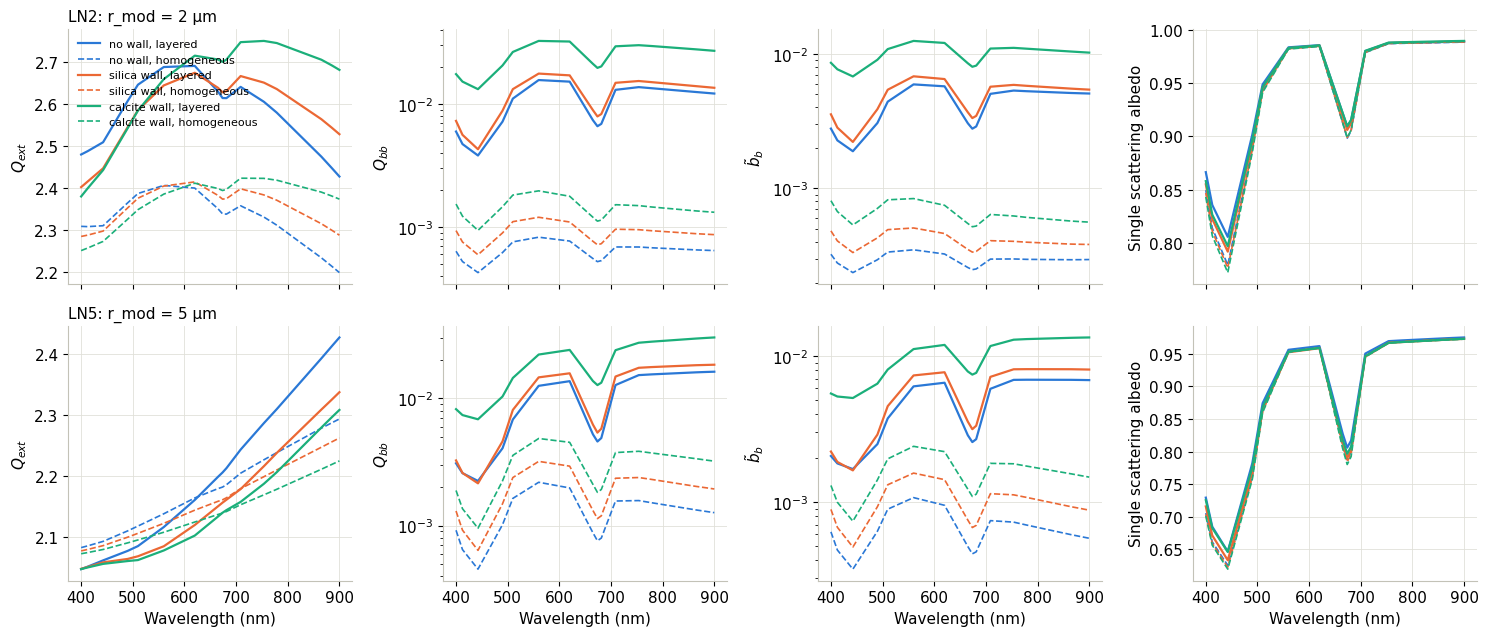

In [12]:
panels = [('Qext', '$Q_{ext}$'), ('Qbb', '$Q_{bb}$'), ('bb_ratio', '$\\tilde{b}_b$'), ('ssa', 'Single scattering albedo')]
fig, axs = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True)
for i, p in enumerate(['LN2', 'LN5']):
    variants = [('no wall', ds2.sel(absorption='pigment', psd=p, m_shell=1.10, f_v=0.25))]
    variants += [(f'{w} wall', ds3.sel(absorption='pigment', psd=p, wall=w)) for w in walls]
    for (name, d), c in zip(variants, CAT):
        for st, ls in [('layered', '-'), ('homogeneous', '--')]:
            for j, (v, label) in enumerate(panels):
                axs[i, j].plot(wl, d[v].sel(structure=st), ls=ls, color=c, lw=1.6 if ls == '-' else 1.2,
                               label=f'{name}, {st}')
                axs[i, j].set_ylabel(label)
    axs[i, 1].set_yscale('log')
    axs[i, 2].set_yscale('log')
    axs[i, 0].set_title(f'{p}: {psd_def[p][1]}', loc='left')
for ax in axs[1]:
    ax.set_xlabel('Wavelength (nm)')
axs[0, 0].legend(frameon=False, fontsize=8)
plt.tight_layout()

In [13]:
sub = ds3.sel(absorption='none', wl=560)
ref = ds2.sel(absorption='none', wl=560, m_shell=1.10, f_v=0.25)
rows = {}
for v in ['Qext', 'bb_ratio', 'g']:
    for w in walls:
        lay = sub[v].sel(wall=w, structure='layered')
        rows[(v, f'{w} wall / no wall')] = (lay / ref[v].sel(structure='layered')).to_pandas()
        rows[(v, f'{w} wall / homogeneous')] = (lay / sub[v].sel(wall=w, structure='homogeneous')).to_pandas()
pd.DataFrame(rows).T.round(2)

psd                                  J3.0  J3.5  J4.0  J4.5  LN0.5    LN1  \
Qext     silica wall / no wall       1.02  1.06  1.10  1.15   1.16   1.07   
         silica wall / homogeneous   1.02  1.02  1.00  0.95   0.99   1.09   
         calcite wall / no wall      1.07  1.15  1.25  1.36   1.36   1.17   
         calcite wall / homogeneous  1.04  1.03  1.00  0.94   1.00   1.11   
bb_ratio silica wall / no wall       1.09  1.07  1.07  1.06   0.91   1.00   
         silica wall / homogeneous   4.95  4.26  2.21  1.31   9.10  13.58   
         calcite wall / no wall      1.64  1.55  1.39  1.22   1.26   1.80   
         calcite wall / homogeneous  5.69  4.96  2.51  1.38  10.67  17.65   
g        silica wall / no wall       1.00  1.00  1.00  0.99   1.00   1.00   
         silica wall / homogeneous   0.98  0.98  0.98  0.98   0.97   0.98   
         calcite wall / no wall      0.99  0.99  0.98  0.98   0.99   0.99   
         calcite wall / homogeneous  0.97  0.97  0.97  0.98   0.97   0.97   

psd                                    LN2   LN5  
Qext     silica wall / no wall        0.98  0.98  
         silica wall / homogeneous    1.10  0.98  
         calcite wall / no wall       0.99  0.98  
         calcite wall / homogeneous   1.11  0.99  
bb_ratio silica wall / no wall        1.09  1.11  
         silica wall / homogeneous   14.58  5.52  
         calcite wall / no wall       1.91  1.56  
         calcite wall / homogeneous  15.37  5.13  
g        silica wall / no wall        1.00  1.00  
         silica wall / homogeneous    0.98  0.98  
         calcite wall / no wall       0.98  0.99  
         calcite wall / homogeneous   0.97  0.97

## Main results

Layered particles are compared with homogeneous spheres of the same size and the same volume-averaged
refractive index $\bar{m}_r$ (all OLCI bands and the eight size distributions):

* **Backscattering is the main signature of the layered structure.** A high-index shell around a low-index core
  raises the backscattering ratio $\tilde{b}_b$ above that of the homogeneous equivalent: by a factor 1.0–2.0 for
  the steep Junge J4.5 distribution, 1.3–4.3 for J4.0, up to 15 for J3.0 and up to 35–50 for the log-normal
  distributions, the largest factors being for a thin dense shell ($f_v$ = 0.10). At a given $\bar{m}_r$, the
  thinner the shell, the larger $\tilde{b}_b$. A homogeneous sphere with the volume-averaged index therefore
  underestimates the backscattering of such cells, and inverting $b_b$ with homogeneous spheres overestimates
  their bulk refractive index.
* **$Q_{ext}$ is only weakly affected** (ratio 0.90–1.14), mostly through a shift of the interference structure
  of the narrow log-normal distributions; the Junge distributions stay within 0.94–1.05.
* **The asymmetry parameter decreases slightly** (ratio 0.93–1.00), consistent with stronger side and back
  scattering.
* **The scattering matrix changes beyond $a_1$:** $-b_1/a_1$ at 90° and $a_3/a_1$ differ from the homogeneous
  case, and $b_2/a_1$ is much larger for coated particles (e.g. 0.1–0.2 instead of ≈ 0 for J4.0).
* **Absorption depends on where the pigment sits.** With the pigment confined to the shell, $Q_{abs}$ is
  0.74–1.11 times that of the homogeneous equivalent. The lowest ratios are for a thin $m_{shell}$ = 1.20 shell
  and large particles (LN5, J3.0) between 500 and 620 nm. The single scattering albedo changes by
  −0.01 to +0.06, the largest increase being in the blue for large particles.
* **An outer wall** (2 % of the radius) increases $\tilde{b}_b$ compared with the same cell without a wall, much
  more for calcite (×1.2–1.9) than for silica (×0.9–1.1) at 560 nm. Compared with the homogeneous equivalent,
  $\tilde{b}_b$ of the three-layer cells is 1.3–18 times higher.

These results are for an idealized concentric geometry. Real cells, with off-centered irregular chloroplasts and
non-spherical shapes, are likely to show smoother angular features; the multilayer results should be taken as
an indication of the sensitivity to internal structure rather than as a model of a given species.

## 5. Saving the results

In [14]:
ofile = odir / 'sensitivity_multilayer_particles.nc'
attrs = dict(refractive_index='relative to seawater, n_w = 1.34', wavelength='OLCI bands in vacuum (nm)',
             radius_range_um=f'{r_min}-{r_max}', method='multilayer Mie theory (scattnlay)')
ds2.drop_vars('theta_rad').assign_attrs(attrs, model='two-layer: core m=1.02 + shell').to_netcdf(
    ofile, group='two_layer', encoding={'F': {'zlib': True, 'complevel': 4}})
ds3.drop_vars('theta_rad').assign_attrs(attrs, model='three-layer: core, chloroplast, wall').to_netcdf(
    ofile, group='three_layer', mode='a', encoding={'F': {'zlib': True, 'complevel': 4}})
print(ofile, f'{ofile.stat().st_size / 1e6:.1f} MB')

/home/harmel/Dropbox/Dropbox/work/git/vrtc/mopsmap_tbx/scatmat/sensitivity/sensitivity_multilayer_particles.nc 58.0 MB
